# 04b · TimesFM-3 Forecasts (Google foundation model)

**Owner:** Max · **Reads:** notebook 01 outputs · **Feeds:** Elena (calibration, ensemble), Prateek (hybrid residual model)

TimesFM-3 is Google's pretrained time series model (released Aug 2026, ~330M parameters). Like Chronos-2, it forecasts each product's next 28 days **with no training on our data**.
It's a decoder-only transformer that reads the sales history in 32-day patches and outputs 9 percentiles (10th–90th).

**Two runs** (same design as 04a, so the two models compare like with like)
| Run | Model name in files | What the model sees |
|---|---|---|
| Zero-shot | `timesfm3_zs` | Sales history only |
| With covariates | `timesfm3_cov` | Sales history + price, discount ratio, SNAP days, events, Christmas |

**Seven windows per run:** `bt_4` … `bt_1`, `val_1`, `val_2`, `test` (same as 04a).

**Output:** `data/forecasts/<model>_<window>.parquet` with columns
`unique_id, ds, model, window, forecast` (the median) + `q0.1 … q0.9`. (TimesFM-3 doesn't output a mean.)

**Runtime:** **Runtime → Change runtime type → T4 GPU**. Start with `SAMPLE = True`, then `SAMPLE = False`.
If Colab disconnects, run everything again: finished windows are skipped.

**License note:** the `timesfm` package code is Apache 2.0; the model weights use Google's TimesFM non-commercial license. Fine for coursework.

## Full California run: what was done (Nov 10, 2026)

> **Run notes added by Prateek.** Max wrote this notebook and ran the 100-product smoke test on Colab (Nov 3). Prateek ran the **full California run** on Nov 10. The notes in boxes like this one explain what was done for that run and what the outputs show. Max's original explanations are unchanged.

**Where it ran:** locally on a Windows PC with an NVIDIA RTX 4070 (12 GB of GPU memory) instead of a Colab T4, because the full run was estimated at 2.5 to 3 hours on a T4 and Colab disconnects long sessions.

**Result:** all **14 forecast files** (2 runs × 7 windows) for all **12,196 California series**, finished in **58 minutes** with no errors.

**What changed from the Colab version (the model code did not change):**
| Change | Why |
|---|---|
| `DRIVE_DIR` = the folder the notebook sits in | No Google Drive mount locally. The data files were copied from Drive `AML_Term_Project/data/` into a local `data/` folder with the same layout |
| `SAMPLE` and `BATCH_SIZE` read from environment variables `TFM_SAMPLE` and `TFM_BATCH` | Lets two small scripts switch between the 100-product test and the full run without editing the notebook |
| The `!pip install` cell is commented out | Packages were installed once in a conda environment named `tfm`: Python 3.11, PyTorch 2.11 (CUDA 12.8 build), `timesfm` 3.0.2 (same version as Colab) |
| The run scripts set `KMP_DUPLICATE_LIB_OK=TRUE` | On Windows, conda and PyTorch each bring a copy of the OpenMP library (used for multi-core CPU math). Two copies crashed the kernel at the plotting step. This setting lets them coexist |
| Added a runtime estimate cell (after section 5) and section 8 (file check) | To estimate the full run time from the test, and to confirm every file is complete |

**How it was run:** `run_test.bat` (100 products, about 30 seconds of forecasting) and then `run_full.bat`. Both run this notebook from top to bottom without a browser (`jupyter nbconvert --execute`) and save the executed copy with all outputs, which is this file. The scripts are in `scripts/04b_local_windows/`.

**Check that the local setup matches Colab:** the 100-product test on the 4070 reproduced Max's Colab MAE (mean absolute error) values exactly to three decimals on all 14 windows (for example, zero-shot test window 0.981 on both).

## 0 · Settings

In [1]:
import os
# LOCAL RUN: run_test.bat sets TFM_SAMPLE=1, run_full.bat sets TFM_SAMPLE=0. Opened by hand in Jupyter, it defaults to the test.
SAMPLE      = os.environ.get("TFM_SAMPLE", "1") == "1"   # True = 100-product smoke test; False = all ~12,200 California series
RUNS        = ["zs", "cov"]   # zero-shot, with covariates
N_BACKTEST  = 4         # extra 28-day windows before val_1 (training data for the hybrid model)
BATCH_SIZE  = int(os.environ.get("TFM_BATCH", "32"))   # set in the .bat files; series per GPU batch; lowered automatically if the GPU runs out of memory
OVERWRITE   = False     # True = redo windows that already have a forecast file

# LOCAL RUN: the project folder is the folder this notebook sits in (Term Project\AML_Term_Project)
DRIVE_DIR   = os.path.abspath(".")
DATA_DIR    = f"{DRIVE_DIR}/data"
OUT_DIR     = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"

MODEL_ID    = "google/timesfm-3.0-pytorch"
COVARIATES  = ["sell_price", "price_ratio", "snap", "is_event", "is_christmas"]   # known in advance for future dates
print("SAMPLE =", SAMPLE, "| BATCH_SIZE =", BATCH_SIZE, "| OUT_DIR =", OUT_DIR)


SAMPLE = False | BATCH_SIZE = 32 | OUT_DIR = C:\Users\achir\OneDrive\MSBA\Deep learning\Term Project\AML_Term_Project/data/forecasts


> **Run note:** for this run `run_full.bat` set `TFM_SAMPLE=0` (all 12,196 series) and `TFM_BATCH=32` (32 series per GPU batch, same as Colab). The printed line above confirms the settings and that outputs went to `data/forecasts`. Everything else in this cell is as Max wrote it.

## 1 · Install and connect

In [2]:
# Installed already in the conda environment (see setup steps), so this is commented out.
# !pip install -q "timesfm[torch]==3.0.2"


In [3]:
import os, json, time, dataclasses
import numpy as np
import pandas as pd
import torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: using the paths in Settings as-is.")

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Set Runtime -> Change runtime type -> T4 GPU, or expect this to be slow.")

Not running in Colab: using the paths in Settings as-is.
Device: cuda | torch 2.11.0+cu128


> **Run note:** `Device: cuda | torch 2.11.0+cu128` confirms the model ran on the GPU, not the CPU. The "Not running in Colab" message is expected: the Drive mount is skipped and the local paths are used.

## 2 · Load data and windows

In [4]:
df = pd.read_parquet(f"{DATA_DIR}/{'ca_sample100' if SAMPLE else 'ca_sales'}.parquet")
df["unique_id"] = df["unique_id"].astype(str)
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

with open(f"{DATA_DIR}/windows.json") as f:
    wjson = json.load(f)
H = wjson["horizon"]

# Shared window list (identical to 04a): 4 backtests right before val_1, then val_1, val_2, test.
val1_start = pd.Timestamp(wjson["val_1"]["start"])
windows = {}
for k in range(N_BACKTEST, 0, -1):
    start = val1_start - pd.Timedelta(days=H * k)
    windows[f"bt_{k}"] = (start, start + pd.Timedelta(days=H - 1))
for name in ["val_1", "val_2", "test"]:
    windows[name] = (pd.Timestamp(wjson[name]["start"]), pd.Timestamp(wjson[name]["end"]))

print(f"{df['unique_id'].nunique():,} series, {len(df):,} rows")
pd.DataFrame({w: {"start": s.date(), "end": e.date()} for w, (s, e) in windows.items()}).T

12,196 series, 18,559,286 rows


,start,end
bt_4,2015-11-09,2015-12-06
bt_3,2015-12-07,2016-01-03
bt_2,2016-01-04,2016-01-31
bt_1,2016-02-01,2016-02-28
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


> **Run note:** 12,196 series and 18,559,286 rows, which matches notebook 01's output. The seven windows are identical to 04a (Chronos-2), so the two foundation models are compared on exactly the same days.

## 3 · Load TimesFM-3

In [5]:
from timesfm3 import TimesFM3Forecaster
model = TimesFM3Forecaster.from_pretrained(MODEL_ID, device=DEVICE, per_core_batch_size=BATCH_SIZE)
QUANTILES = list(model.config.quantiles)
print("Loaded", MODEL_ID, "| quantiles:", QUANTILES)

Loaded google/timesfm-3.0-pytorch | quantiles: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


## 4 · Forecast one window
TimesFM-3 takes one array per product rather than a table:
- **Context** = the product's sales before the window starts (the model never sees the window's actual sales)
- **Covariates** (cov run) = one array per covariate covering the history **and** the 28 window days.
  The model reads the extra 28 values as "known future" inputs.
- Products launched on or after the window start have no history, so they're skipped for that window

In [6]:
def build_inputs(run, start, end):
    hist = df[df["ds"] < start]
    ids = hist["unique_id"].unique()
    fut = df[(df["ds"] >= start) & (df["ds"] <= end) & df["unique_id"].isin(ids)]
    if run == "cov":
        n_fut = fut.groupby("unique_id").size()
        ids = n_fut[n_fut == H].index.values          # need all 28 future rows for covariates
    hist_g = dict(tuple(hist[hist["unique_id"].isin(ids)].groupby("unique_id", sort=True)))
    fut_g = dict(tuple(fut[fut["unique_id"].isin(ids)].groupby("unique_id", sort=True))) if run == "cov" else {}

    ids = sorted(hist_g)
    contexts, covs = [], []
    for uid in ids:
        h = hist_g[uid]
        contexts.append(h["y"].to_numpy(np.float32))
        if run == "cov":
            both = pd.concat([h[COVARIATES], fut_g[uid][COVARIATES]])
            covs.append(both.to_numpy(np.float32).T)    # shape (n_covariates, context + 28)
    return ids, contexts, (covs if run == "cov" else None)


def forecast_window(run, wname, start, end, batch_size=BATCH_SIZE):
    ids, contexts, covs = build_inputs(run, start, end)
    while True:
        try:
            model.config = dataclasses.replace(model.config, per_core_batch_size=batch_size)
            outs = list(model.predict_batch(
                contexts=contexts, horizon=H, past_future_covariates=covs,
                ts_ids=ids, return_quantiles=True, make_positive=True,
            ))
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            batch_size //= 2
            print(f"  GPU out of memory -> retrying with batch_size={batch_size}")
            if batch_size < 1:
                raise

    dates = pd.date_range(start, periods=H, freq="D")
    q = np.stack([o.quantiles for o in outs])          # (series, 28, n_quantiles)
    res = pd.DataFrame({
        "unique_id": np.repeat([o.ts_id for o in outs], H),
        "ds": np.tile(dates, len(outs)),
        "model": f"timesfm3_{run}",
        "window": wname,
        "forecast": np.concatenate([o.forecast for o in outs]).clip(min=0).astype("float32"),   # median
    })
    for j, ql in enumerate(QUANTILES):
        res[f"q{ql}"] = q[:, :, j].ravel().clip(min=0).astype("float32")
    return res, batch_size

## 5 · Run everything (skips windows already saved)

In [7]:
log_rows = []
for run in RUNS:
    for wname, (start, end) in windows.items():
        path = f"{OUT_DIR}/timesfm3_{run}_{wname}.parquet"
        if os.path.exists(path) and not OVERWRITE:
            print(f"skip  timesfm3_{run:3s} {wname:6s} (already saved)")
            continue
        t0 = time.time()
        res, used_bs = forecast_window(run, wname, start, end)
        res.to_parquet(path, index=False)
        secs = time.time() - t0
        n = res["unique_id"].nunique()
        print(f"done  timesfm3_{run:3s} {wname:6s} {n:6,} series  {secs:6.1f}s")
        log_rows.append({"model": f"timesfm3_{run}", "window": wname, "series": n, "seconds": round(secs, 1),
                         "batch_size": used_bs, "device": DEVICE, "sample": SAMPLE,
                         "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")})

if log_rows:
    log_path = f"{OUT_DIR}/run_log.csv"
    new = pd.DataFrame(log_rows)
    new.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    display(new)

done  timesfm3_zs  bt_4   12,175 series   128.4s


done  timesfm3_zs  bt_3   12,177 series   128.9s


done  timesfm3_zs  bt_2   12,185 series   130.8s


done  timesfm3_zs  bt_1   12,190 series   132.9s


done  timesfm3_zs  val_1  12,196 series   136.3s


done  timesfm3_zs  val_2  12,196 series   135.7s


... (5 outputs left out)

done  timesfm3_cov val_1  12,196 series   358.3s


done  timesfm3_cov val_2  12,196 series   358.1s


done  timesfm3_cov test   12,196 series   365.2s


,model,window,series,seconds,batch_size,device,sample,run_at
0,timesfm3_zs,bt_4,12175,128.4,32,cuda,False,2026-11-10 02:54
1,timesfm3_zs,bt_3,12177,128.9,32,cuda,False,2026-11-10 02:56
2,timesfm3_zs,bt_2,12185,130.8,32,cuda,False,2026-11-10 02:58
3,timesfm3_zs,bt_1,12190,132.9,32,cuda,False,2026-11-10 03:00
4,timesfm3_zs,val_1,12196,136.3,32,cuda,False,2026-11-10 03:02
5,timesfm3_zs,val_2,12196,135.7,32,cuda,False,2026-11-10 03:05
6,timesfm3_zs,test,12196,136.9,32,cuda,False,2026-11-10 03:07
7,timesfm3_cov,bt_4,12175,336.9,32,cuda,False,2026-11-10 03:13
8,timesfm3_cov,bt_3,12177,341.3,32,cuda,False,2026-11-10 03:18
9,timesfm3_cov,bt_2,12185,348.2,32,cuda,False,2026-11-10 03:24


> **Run note: what section 5 shows**
> * **Speed:** zero-shot took about **2.2 minutes per window** (15.5 minutes for all 7), and with covariates about **5.8 minutes per window** (41 minutes). Total **58 minutes**, compared with Max's estimate of about 2.6 hours on a Colab T4. The covariates run is about 2.6 times slower because the model also reads the five covariate series for every product.
> * **Batch size:** stayed at 32 for every window, so the GPU never ran out of memory.
> * **Series counts:** 12,175 to 12,190 in the backtest windows and 12,196 from val_1 on. A few products launch partway through the data and have no history before the earliest windows, so they are skipped there. Chronos-2 skipped the same products.

In [8]:
# LOCAL RUN: estimate of the full California run time from this test (only meaningful when SAMPLE = True)
if SAMPLE and log_rows:
    total = sum(r["seconds"] for r in log_rows)
    n_test = df["unique_id"].nunique()
    est_h = total * (12196 / n_test) / 3600
    print(f"Test took {total:.0f} s for {len(log_rows)} windows -> full run estimate about {est_h:.1f} hours (a bit high: includes per-window startup time)")


> **Run note:** this cell only prints something in the 100-product test (`SAMPLE = True`). In that test, all 14 windows took 30 seconds, which predicted about 1 hour for the full run. The actual time was 58 minutes.

## 6 · Quick check against the baseline and Chronos-2
Not the official evaluation (that's notebook 05). This confirms the forecasts are sensible and gives a first look
at how TimesFM-3 compares with Chronos-2 (if 04a has already been run on the same data).

In [9]:
actual = df[["unique_id", "ds", "y"]]
lag7 = actual.copy()
lag7["ds"] = lag7["ds"] + pd.Timedelta(days=7)
lag7 = lag7.rename(columns={"y": "naive"})

rows = []
for run in RUNS:
    for wname in windows:
        f = pd.read_parquet(f"{OUT_DIR}/timesfm3_{run}_{wname}.parquet")
        m = f.merge(actual, on=["unique_id", "ds"]).merge(lag7, on=["unique_id", "ds"], how="left")
        m["naive"] = m["naive"].fillna(0)
        row = {"run": run, "window": wname,
               "MAE timesfm3": (m["forecast"] - m["y"]).abs().mean(),
               "MAE naive": (m["naive"] - m["y"]).abs().mean()}
        cpath = f"{OUT_DIR}/chronos2_{run}_{wname}.parquet"
        if os.path.exists(cpath):     # same products, same days -> fair side-by-side
            c = pd.read_parquet(cpath)[["unique_id", "ds", "forecast"]].rename(columns={"forecast": "chronos"})
            mc = m.merge(c, on=["unique_id", "ds"])
            row["MAE chronos2"] = (mc["chronos"] - mc["y"]).abs().mean()
        rows.append(row)
check = pd.DataFrame(rows)
check["improvement vs naive"] = (1 - check["MAE timesfm3"] / check["MAE naive"]).map("{:.0%}".format)
check.round(3)

,run,window,MAE timesfm3,MAE naive,improvement vs naive
0,zs,bt_4,0.917,1.206,24%
1,zs,bt_3,0.918,1.210,24%
2,zs,bt_2,0.932,1.218,23%
3,zs,bt_1,0.964,1.250,23%
4,zs,val_1,0.984,1.275,23%
5,zs,val_2,0.991,1.291,23%
6,zs,test,1.016,1.325,23%
7,cov,bt_4,0.913,1.206,24%
8,cov,bt_3,0.906,1.210,25%
9,cov,bt_2,0.928,1.218,24%


> **Run note: how to read the table above**
>
> **Caution about the "naive" column:** as logged on Nov 10, this quick check's lag-7 baseline uses actual sales from inside the forecast window from day 8 on, so it is not an honest baseline. Use the baselines from `02a_seasonal_naive.ipynb` (`snaive`, `smean4`) and the official scores from `05_evaluation.ipynb` in the write-up. The TimesFM-3 MAE values themselves are not affected.
>
> **No Chronos-2 column:** Chronos-2's forecast files were not in the local folder, so this table could not show them. From Max's Nov 3 log (same products, same days):
>
> | Window | Chronos-2 zero-shot | TimesFM-3 zero-shot | Chronos-2 + covariates | TimesFM-3 + covariates |
> |---|---|---|---|---|
> | val_1 | 0.986 | **0.984** | 0.987 | **0.974** |
> | val_2 | 0.995 | **0.991** | 0.993 | **0.981** |
> | test | 1.026 | **1.016** | 1.028 | **1.014** |
>
> **What this shows (to be confirmed by notebook 05):**
> * TimesFM-3 has a slightly lower MAE than Chronos-2 on every window above, by 0.2% to 1.4%. That is small enough to call the two models roughly tied.
> * Covariates (prices, SNAP days, events) lower TimesFM-3's MAE on **all 7 windows**, but only by 0.2% to 1.3%. For Chronos-2 they made no difference. So covariates help TimesFM-3 a little, but neither model gains much from them.
> * Error rises from the backtests (about 0.91) to the test window (about 1.01). The naive baseline's error rises the same way, so the later windows are simply harder to forecast, not a sign that the model got worse.

## 7 · Look at a few products
Actual sales (black) vs. TimesFM-3's median and 10th–90th percentile range on the **test** window.

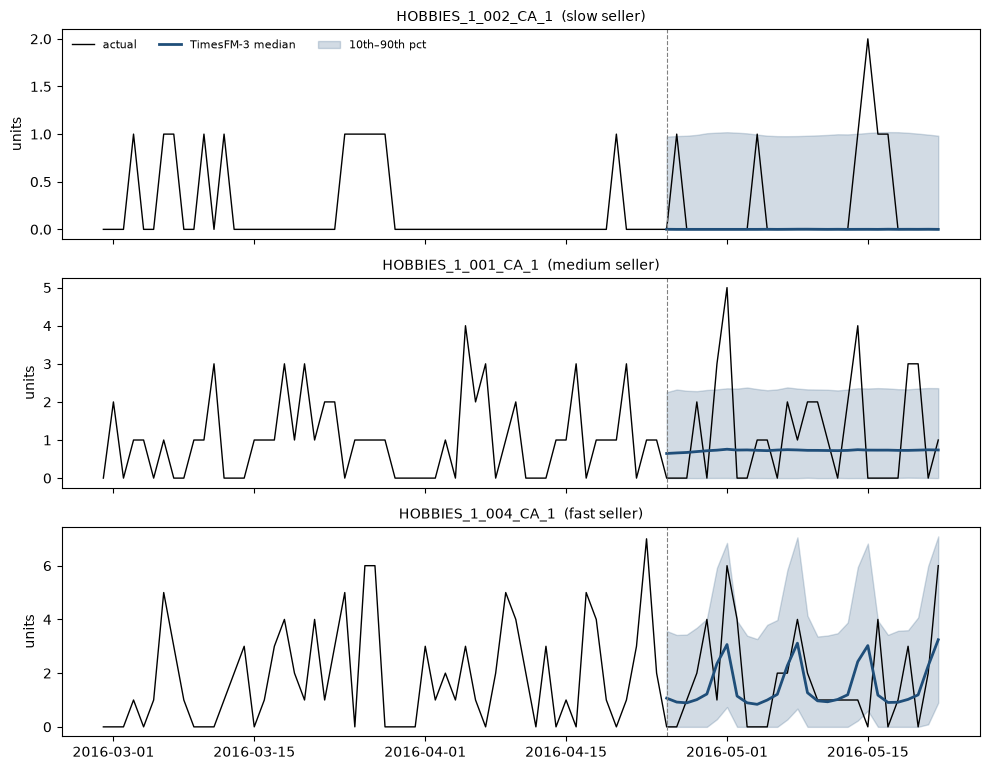

In [10]:
import matplotlib.pyplot as plt
run = "cov" if "cov" in RUNS else RUNS[0]
f = pd.read_parquet(f"{OUT_DIR}/timesfm3_{run}_test.parquet")
start, end = windows["test"]
static = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
static["unique_id"] = static["unique_id"].astype(str)
pick = (static[static["unique_id"].isin(f["unique_id"])]
        .groupby("sales_speed", observed=True)["unique_id"].first())

fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.6 * len(pick)), sharex=True)
for ax, (speed, uid) in zip(np.atleast_1d(axes), pick.items()):
    hist = df[(df["unique_id"] == uid) & (df["ds"] >= start - pd.Timedelta(days=56)) & (df["ds"] <= end)]
    fc = f[f["unique_id"] == uid]
    ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="actual")
    ax.plot(fc["ds"], fc["forecast"], color="#1f4e79", lw=2, label="TimesFM-3 median")
    ax.fill_between(fc["ds"], fc["q0.1"], fc["q0.9"], color="#1f4e79", alpha=0.2, label="10th–90th pct")
    ax.axvline(start, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{uid}  ({speed} seller)", fontsize=10); ax.set_ylabel("units")
np.atleast_1d(axes)[0].legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()
if not SAMPLE:
    os.makedirs(f"{DATA_DIR}/figures", exist_ok=True)
    plt.savefig(f"{DATA_DIR}/figures/11_timesfm3_examples.png", dpi=150, bbox_inches="tight")
plt.show()

> **Run note: what the plot shows** (covariates run, test window; also saved to `figures/11_timesfm3_examples.png`)
> * **Slow seller (HOBBIES_1_002_CA_1):** the median forecast is **flat at zero** for all 28 days, while the product actually sold on 5 of them. This is the same problem seen with Chronos-2. For mean absolute error, predicting zero for a product that usually sells nothing is the "best" guess, but it plans no stock at all.
> * **Medium seller (HOBBIES_1_001_CA_1):** the median is flat at about 0.7 units/day. The 10th to 90th percentile band (0 to about 2.3 units) contains most days, but the spikes of 3 to 5 units fall outside it.
> * **Fast seller (HOBBIES_1_004_CA_1):** the model picks up the **weekly pattern** (peaks every 7 days), but its peaks of about 3 units are lower than the actual peaks of 4 to 6.

## What to report back
Download this notebook (**File → Download → .ipynb**) with outputs into *Project Code*; Claude commits it to GitHub.
Look at:
1. Section 5: seconds per window
2. Section 6: does TimesFM-3 beat the naive baseline? How does it compare with Chronos-2? Does `cov` help?
3. Section 7: compare these plots with 04a's. Does TimesFM-3 also forecast low for spiky products?

> **Run note:** the Colab instructions above do not apply to the local run. This executed notebook was added to the GitHub repo directly, and the forecast files were uploaded to Drive `AML_Term_Project/data/forecasts/`.

## 8 · Local check of the saved files (added for the local run)
Expect 14 files, up to 12,196 series each (a few fewer in the earliest backtests), rows = series × 28, and 0 missing forecasts.

In [11]:
import glob
rows = []
for p in sorted(glob.glob(f"{OUT_DIR}/timesfm3_*.parquet")):
    f = pd.read_parquet(p)
    rows.append({"file": os.path.basename(p), "series": f["unique_id"].nunique(), "rows": len(f),
                 "rows_ok": len(f) == f["unique_id"].nunique() * H, "missing": int(f["forecast"].isna().sum()),
                 "negative": int((f["forecast"] < 0).sum())})
summary = pd.DataFrame(rows)
print(len(summary), "files found (expect 14)")
summary

14 files found (expect 14)


,file,series,rows,rows_ok,missing,negative
0,timesfm3_cov_bt_1.parquet,12190,341320,True,0,0
1,timesfm3_cov_bt_2.parquet,12185,341180,True,0,0
2,timesfm3_cov_bt_3.parquet,12177,340956,True,0,0
3,timesfm3_cov_bt_4.parquet,12175,340900,True,0,0
4,timesfm3_cov_test.parquet,12196,341488,True,0,0
5,timesfm3_cov_val_1.parquet,12196,341488,True,0,0
6,timesfm3_cov_val_2.parquet,12196,341488,True,0,0
7,timesfm3_zs_bt_1.parquet,12190,341320,True,0,0
8,timesfm3_zs_bt_2.parquet,12185,341180,True,0,0
9,timesfm3_zs_bt_3.parquet,12177,340956,True,0,0


> **Run note: file check results and extra checks**
>
> All 14 files are complete: every product has exactly 28 days (`rows_ok` True), with no missing and no negative forecasts.
>
> Extra checks on the **test window**, done after the run by comparing the files with the actual sales in `ca_sales.parquet`:
>
> | Check | Zero-shot | With covariates | What it means |
> |---|---|---|---|
> | MAE recomputed from the files | 1.016 | 1.014 | Matches section 6, so the saved files are the ones scored |
> | Total forecast units ÷ total actual units | **0.73** | **0.72** | The median forecast under-predicts total demand by about 27% |
> | Share of forecasts below 0.5 units | 55% | 58% | Slightly more than the share of days with zero sales (51%) |
> | Share of actual sales inside the 10th to 90th percentile range | **83%** | **85%** | Close to the 80% it should be, so the percentile forecasts are well calibrated |
> | Percentiles in increasing order, and `forecast` equals `q0.5` | Yes | Yes | The file format is correct |
>
> The 27% under-forecast of total units is the same pattern found for Chronos-2. It is the main reason for the calibration step (Elena) and the hybrid residual model (Prateek). Because the percentile ranges are reliable, the higher percentiles (for example `q0.8` or `q0.9`) are a reasonable input for safety-stock sizing.

## Summary of the full run (Nov 10, 2026)

**Outputs**
* 14 forecast files `timesfm3_{zs,cov}_{bt_4 … test}.parquet` and `run_log.csv` in Drive `AML_Term_Project/data/forecasts/` (not in GitHub, because data files are kept in Drive)
* `figures/11_timesfm3_examples.png`
* This executed notebook

**Main findings (quick check; official numbers come from notebook 05)**
1. TimesFM-3 and Chronos-2 are **roughly tied**. TimesFM-3's MAE is 0.2% to 1.4% lower on the windows compared.
2. Covariates help TimesFM-3 **slightly** (0.2% to 1.3% lower MAE on every window), while they made no difference for Chronos-2.
3. Like Chronos-2, TimesFM-3's median forecast **under-predicts total demand by about 27%** and predicts flat zero for slow sellers.
4. Its 10th to 90th percentile ranges are **well calibrated** (83% to 85% coverage against an 80% target).
5. On an RTX 4070 the full run takes **58 minutes**, about 2.5 times faster than the Colab T4 estimate.

**Next steps**
* Re-run `05_evaluation.ipynb` so TimesFM-3 is included in the official scores and safety-stock dollars.
* The backtest files (`bt_1` to `bt_4`) are the training data for the hybrid residual model, and val_1 and val_2 feed calibration and the ensemble.